# Task 1: Clustering
Segment the users by how they charge and find a target audience for the ad campaigns.

Sections: 1. Data, 2. Hourly energy and occupation, 3. Users and features, 4. Method selection, 5. Final segmentation, 6. Segment characteristics, 7. Findings

## Business case

The company wants a target audience for its next ad campaigns. We break that into three questions:

1. Who is similar? We group users by when they charge (weekdays vs. weekends, time of day).
2. When can a segment be reached, and with what? The hours a segment charges in tell when an ad or an offer, e.g. a discount in quiet hours, would reach it.
3. Is a segment worth targeting? Volume (how often, kWh per session, how long they stay), station loyalty and home area say how valuable a segment is.

So we cluster on timing only and use the other variables afterwards to describe the segments.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples

## 1. Data

Which of the 33 variables do we need? We load all of them first to get an overview.

In [30]:
d = pd.read_csv("EVChargingStationUsage.csv", dtype={"User ID": str}, low_memory=False)
print(f"{len(d)} sessions, {d['User ID'].nunique()} users")

overview = pd.DataFrame({"unique values": d.nunique(),
                         "% missing": 100 * d.isna().mean(),
                         "% most common value": [100 * d[c].value_counts(normalize=True).iloc[0] for c in d.columns]})
overview.round(1)

259415 sessions, 21441 users


,unique values,% missing,% most common value
Station Name,47,0.0,9.1
MAC Address,83,0.0,5.7
Org Name,2,0.0,91.3
Start Date,244798,0.0,0.0
Start Time Zone,3,0.0,64.3
End Date,244159,0.0,0.0
End Time Zone,3,0.0,64.3
Transaction Date (Pacific Time),240905,0.1,0.0
Total Duration (hh:mm:ss),31025,0.0,0.0
Charging Time (hh:mm:ss),22473,0.0,0.0


GHG and gasoline savings are probably just computed from energy, and the fee probably depends more on the year than on the user. We check both.

In [31]:
print(f"correlation of Energy with GHG savings: {d['Energy (kWh)'].corr(d['GHG Savings (kg)']):.1f}")
print(f"correlation of Energy with gasoline savings: {d['Energy (kWh)'].corr(d['Gasoline Savings (gallons)']):.1f}")
print("\nshare of sessions with a fee, per year:")
print((d["Fee"] > 0).groupby(pd.to_datetime(d["Start Date"]).dt.year).mean().round(2).to_string())

correlation of Energy with GHG savings: 1.0
correlation of Energy with gasoline savings: 1.0

share of sessions with a fee, per year:
Start Date
2011    0.00
2012    0.00
2013    0.00
2014    0.00
2015    0.00
2016    0.00
2017    0.33
2018    0.99
2019    0.99
2020    0.99


We keep seven variables: who charges (User ID), when (Start Date), for how long (parking and charging time), how much (Energy), where (Station Name) and where the driver lives (Driver Postal Code). The other 26 are left out:

| Variables | Why they are left out |
|---|---|
| Org Name, City, State/Province, Country, County, Currency, Port Type, Plug Type | few unique values, and the most common one covers most of the sessions |
| GHG Savings, Gasoline Savings | correlation very high with energy (1.0) |
| End Date, Transaction Date | the end time is the start time plus the parking duration |
| Start/End Time Zone | only used to remove the UTC sessions (below) |
| MAC Address, EVSE ID, System S/N, Model Number, Address 1, Postal Code, Latitude, Longitude, Port Number | hardware and location details; Station Name already tells where a session is |
| Plug In Event Id | a session identifier |
| Fee | charging was free until 2017, so the fee mostly reflects the year |
| Ended By | how the session ended (mostly plug-out at the vehicle), which says nothing about when or how much a user charges |

The times look like local time, since the time zone label switches between PDT and PST with daylight saving time. 32 sessions are labelled UTC, and we remove them because we can't tell whether their times are shifted.

In [32]:
len_before = len(d)
d = d[(d["Start Time Zone"] != "UTC") & (d["End Time Zone"] != "UTC")]
print(f"Removed: {len_before - len(d)} sessions")

Removed: 32 sessions


In [33]:
columns = ["User ID", "Start Date", "Total Duration (hh:mm:ss)", "Charging Time (hh:mm:ss)", "Energy (kWh)", "Station Name", "Driver Postal Code"]
d = d[columns].copy()

d["Start Date"] = pd.to_datetime(d["Start Date"])
d["Parking Duration"] = pd.to_timedelta(d["Total Duration (hh:mm:ss)"])
d["Charging Duration"] = pd.to_timedelta(d["Charging Time (hh:mm:ss)"])
d = d.drop(columns=["Total Duration (hh:mm:ss)", "Charging Time (hh:mm:ss)"])
print(f"{len(d)} sessions, {d['User ID'].nunique()} users, {d['Start Date'].min():%Y-%m-%d} to {d['Start Date'].max():%Y-%m-%d}")

259383 sessions, 21439 users, 2011-07-29 to 2020-12-31


### Cleaning

Can all sessions be used? Two kinds look unusable:

- sessions without a user ID, since they can't be assigned to anyone
- sessions where the charging time is longer than the parking time, which can't happen, so we treat them as faulty

In [34]:
l1 = len(d)
d = d.dropna(subset=["User ID"])
l2 = len(d)
d = d[d["Charging Duration"] <= d["Parking Duration"]].reset_index(drop=True)
l3 = len(d)
print(f"Removed {l1 - l2} sessions without user ID ({(l1 - l2) / l1:.1%}) and {l2 - l3} sessions where charging lasts longer than parking")

Removed 7674 sessions without user ID (3.0%) and 42 sessions where charging lasts longer than parking


About 3 % of the sessions are removed, almost all because the user ID is missing.

### Sessions

What does a typical session look like? We convert the durations to hours and cut the histograms at the 99th percentile (rounded up), since a few very long sessions would otherwise stretch the axes.

In [35]:
d["Charging Hours"] = d["Charging Duration"].dt.total_seconds() / 3600
d["Parking Hours"] = d["Parking Duration"].dt.total_seconds() / 3600

np.ceil(d[["Energy (kWh)", "Charging Hours", "Parking Hours"]].quantile([0.99]))

,Energy (kWh),Charging Hours,Parking Hours
0.99,37.0,7.0,12.0


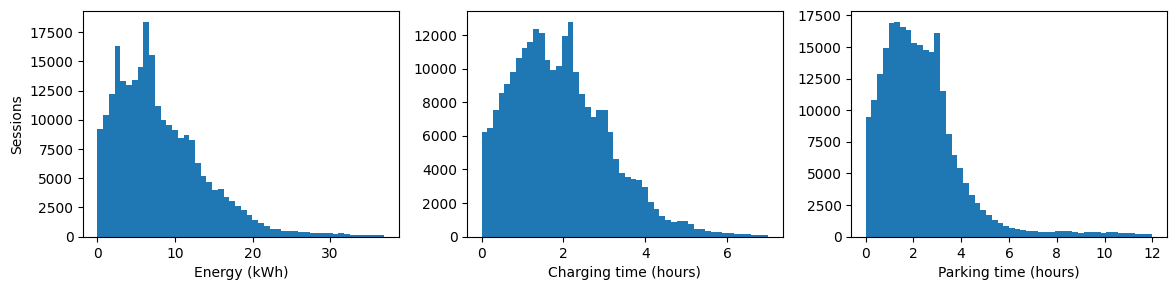

,Energy (kWh),Charging Hours,Parking Hours
count,251667.00,251667.00,251667.00
mean,8.52,1.99,2.48
std,7.11,1.37,2.20
min,0.01,0.00,0.02
25%,3.78,1.04,1.17
50%,6.86,1.82,2.09
75%,11.46,2.70,3.09
max,97.36,22.93,114.54


In [36]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(d["Energy (kWh)"], bins=50, range=(0, 37))
ax[0].set(xlabel="Energy (kWh)", ylabel="Sessions")
ax[1].hist(d["Charging Hours"], bins=50, range=(0, 7))
ax[1].set(xlabel="Charging time (hours)")
ax[2].hist(d["Parking Hours"], bins=50, range=(0, 12))
ax[2].set(xlabel="Parking time (hours)")
plt.tight_layout()
plt.show()

d[["Energy (kWh)", "Charging Hours", "Parking Hours"]].describe().round(2)

All three distributions are right-skewed. The median session delivers about 7 kWh over 1.8 hours of charging, and the car is parked for about 2.1 hours. Most sessions last more than an hour, so they cover several clock hours. The next section deals with that.

## 2. Hourly energy and occupation

To compare when users charge, we need energy and occupation per clock hour instead of per session. Each session is spread over the clock hours it covers, in proportion to the time it spends in each hour.

Energy is spread over the charging time (start to start + charging duration). This assumes the car starts charging when it is plugged in and charges at a constant rate. Occupation is spread over the parking time (start to start + parking duration), which gives occupied charger-hours per hour.

If this works, the hourly totals should equal the session totals.

In [37]:
def spread_over_hours(start, duration):
    end = start + duration
    first_hour = start.dt.floor("h")
    n_hours = ((end.dt.floor("h") - first_hour) // pd.Timedelta("1h") + 1).values
    session = np.repeat(np.arange(len(start)), n_hours)
    hour_number = np.arange(len(session)) - np.repeat(n_hours.cumsum() - n_hours, n_hours)
    hour = first_hour.values[session] + hour_number * np.timedelta64(1, "h")
    overlap = np.minimum(end.values[session], hour + np.timedelta64(1, "h")) - np.maximum(start.values[session], hour)
    fraction = overlap / duration.values[session]
    return pd.DataFrame({"User ID": d["User ID"].values[session], "Hour": hour, "Session": session, "Fraction": fraction})

charging = spread_over_hours(d["Start Date"], d["Charging Duration"])
charging["Energy (kWh)"] = charging["Fraction"] * d["Energy (kWh)"].values[charging["Session"].values]
parking = spread_over_hours(d["Start Date"], d["Parking Duration"])
parking["Occupation (h)"] = parking["Fraction"] * d["Parking Hours"].values[parking["Session"].values]

energy_hourly = charging.groupby(["User ID", "Hour"])["Energy (kWh)"].sum()
occupation_hourly = parking.groupby(["User ID", "Hour"])["Occupation (h)"].sum()
hourly = pd.concat([energy_hourly, occupation_hourly], axis=1).fillna(0).reset_index()
hourly["Hour of Day"] = hourly["Hour"].dt.hour
hourly["Weekend"] = hourly["Hour"].dt.dayofweek >= 5

print(f"{len(hourly)} user-hours")
print(f"difference in total energy: {hourly['Energy (kWh)'].sum() - d['Energy (kWh)'].sum():.2f} kWh")
print(f"difference in total occupation: {hourly['Occupation (h)'].sum() - d['Parking Hours'].sum():.2f} h")

864861 user-hours
difference in total energy: 0.00 kWh
difference in total occupation: 0.00 h


### Hourly pattern of all users

Do the days of the week look different? We plot the average energy and occupation per hour for each day. If the days fall into clear groups, those groups can be used to describe users. The correlation between the hourly energy shapes of the days is shown below the plot.

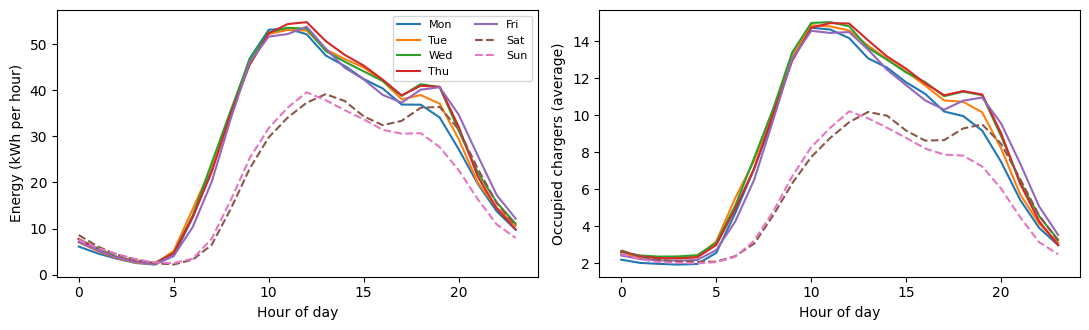

kWh per day: {'Mon': 653, 'Tue': 674, 'Wed': 688, 'Thu': 688, 'Fri': 677, 'Sat': 505, 'Sun': 472}


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Mon,1.00,1.00,1.00,1.00,0.99,0.88,0.95
Tue,1.00,1.00,1.00,1.00,0.99,0.89,0.96
Wed,1.00,1.00,1.00,1.00,1.00,0.91,0.96
Thu,1.00,1.00,1.00,1.00,1.00,0.91,0.97
Fri,0.99,0.99,1.00,1.00,1.00,0.92,0.96
Sat,0.88,0.89,0.91,0.91,0.92,1.00,0.97
Sun,0.95,0.96,0.96,0.97,0.96,0.97,1.00


In [38]:
days = pd.date_range(d["Start Date"].min().date(), d["Start Date"].max().date())
n_days = pd.Series(days.dayofweek).value_counts().sort_index()
n_weekdays = n_days.iloc[:5].sum()
n_weekend_days = n_days.iloc[5:].sum()

measures = ["Energy (kWh)", "Occupation (h)"]
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hourly["Day"] = hourly["Hour"].dt.dayofweek
by_day = {m: hourly.groupby(["Hour of Day", "Day"])[m].sum().unstack("Day") / n_days for m in measures}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, (measure, label) in enumerate([("Energy (kWh)", "Energy (kWh per hour)"), ("Occupation (h)", "Occupied chargers (average)")]):
    for day in range(7):
        ax[i].plot(by_day[measure][day], label=day_names[day], linestyle="-" if day < 5 else "--")
    ax[i].set(xlabel="Hour of day", ylabel=label)
ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print("kWh per day:", dict(zip(day_names, by_day["Energy (kWh)"].sum().round().astype(int))))
shape = (by_day["Energy (kWh)"] / by_day["Energy (kWh)"].sum()).set_axis(day_names, axis=1)
shape.corr().round(2)

Monday to Friday look almost the same: the hourly shapes correlate 0.99-1.00 and each day has 653-688 kWh. Saturday and Sunday are lower (505 and 472 kWh), peak a bit later and correlate 0.97 with each other, but only 0.88-0.97 with the weekdays. Occupation follows nearly the same shape as energy.

The days fall into two groups, so we use the weekday/weekend split together with the hour of day to describe users.

## 3. Users and features

### Which users

How many sessions do users have? Many seem to charge only a few times, and a profile built from one or two sessions can be fragile. We look at how many users and sessions are left for different minimum numbers of sessions.

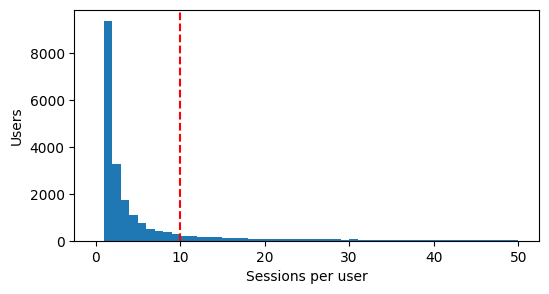

,users,% of users,% of sessions
min. sessions,,,
1,21439,100.0,100.0
3,8802,41.1,93.7
5,5978,27.9,89.9
10,3607,16.8,83.7
20,2215,10.3,76.2
50,1025,4.8,61.9


In [39]:
sessions_per_user = d.groupby("User ID").size()

rows = []
for t in [1, 3, 5, 10, 20, 50]:
    kept = sessions_per_user >= t
    rows.append({"min. sessions": t, "users": kept.sum(), "% of users": 100 * kept.mean(), "% of sessions": 100 * sessions_per_user[kept].sum() / len(d)})

plt.figure(figsize=(6, 3))
plt.hist(sessions_per_user, bins=50, range=(0, 50))
plt.axvline(10, color="red", linestyle="--")
plt.xlabel("Sessions per user")
plt.ylabel("Users")
plt.show()

pd.DataFrame(rows).set_index("min. sessions").round(1)

Most users have only a few sessions, but the users with many sessions make up most of the sessions. Users with at least 10 sessions are about 17 % of the users (3,607) and cover about 84 % of all sessions. A threshold of 5 adds about 2,400 users and 6 % more sessions, but each of those profiles is built from only 5-9 sessions. A threshold of 20 drops the coverage to 76 %.

We use 10 as a compromise between enough sessions per profile and keeping most of the activity, and check the choice again in section 6.

### Which features

Following the business case, users are compared on when they charge. Each user is described by the shape of their own usage:

- share of the user's energy in each hour of the day (24 features)
- share of the user's occupation in each hour of the day (24 features)
- share of energy and of occupation on weekends (2 features)

Using shares removes how much a user charges, so the clusters only describe when. Volume (sessions per week, kWh per session, stay length) is used later to describe the segments (section 6).

This is built into a function so we can use it again later.

In [40]:
def user_features(users):
    h = hourly[hourly["User ID"].isin(users)]
    energy = h.pivot_table(index="User ID", columns="Hour of Day", values="Energy (kWh)", aggfunc="sum", fill_value=0)
    occupation = h.pivot_table(index="User ID", columns="Hour of Day", values="Occupation (h)", aggfunc="sum", fill_value=0)
    total = h.groupby("User ID")[measures].sum()
    weekend_total = h[h["Weekend"]].groupby("User ID")[measures].sum()
    return pd.concat([energy.div(energy.sum(axis=1), axis=0).add_prefix("Energy share h"),
                      occupation.div(occupation.sum(axis=1), axis=0).add_prefix("Occupation share h"),
                      (weekend_total / total).fillna(0).rename(columns={"Energy (kWh)": "Weekend energy share", "Occupation (h)": "Weekend occupation share"})], axis=1)

MIN_SESSIONS = 10
X = user_features(sessions_per_user[sessions_per_user >= MIN_SESSIONS].index)
energy_cols = list(X.filter(like="Energy share h").columns)
print(X.shape)

(3607, 50)


One row per user (3,607 users) and 50 features, all shares between 0 and 1.

## 4. Method selection

Before the final segmentation we need to decide how to represent the features, which algorithm to use and how many clusters.

Do the features need to be standardized? They are all shares between 0 and 1, but some hours may vary much more than others, so we check the standard deviation per hour.

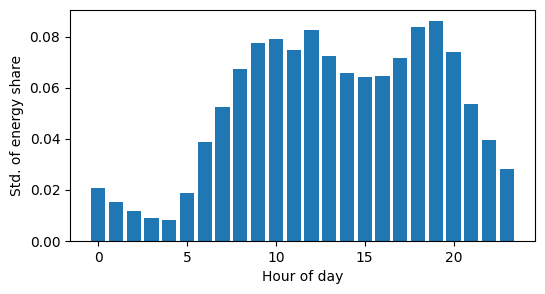

In [41]:
plt.figure(figsize=(6, 3))
plt.bar(range(24), X[energy_cols].std())
plt.xlabel("Hour of day")
plt.ylabel("Std. of energy share")
plt.show()

The night hours vary much less than the busy hours (std. about 0.01-0.02 against about 0.08). Since all the features are shares in the same unit, there is no need to standardize. Standardizing would also give the quiet night hours as much weight as the busy hours, which most likely just amplifies noise.

The 50 features are strongly correlated (neighbouring hours, energy and occupation), so we reduce them with PCA and keep components until at least 80 % of the variance is explained. PCA on the standardized features (correlation PCA) is included for comparison.

Components for 80 % of the variance: shares 5, standardized 8


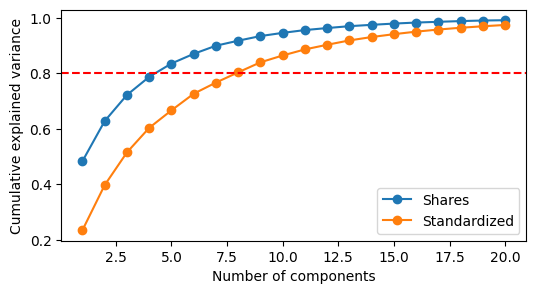

In [42]:
X_std = (X - X.mean()) / X.std()
cumulative = np.cumsum(PCA().fit(X).explained_variance_ratio_)
cumulative_std = np.cumsum(PCA().fit(X_std).explained_variance_ratio_)
q = np.argmax(cumulative >= 0.8) + 1
print(f"Components for 80 % of the variance: shares {q}, standardized {np.argmax(cumulative_std >= 0.8) + 1}")

plt.figure(figsize=(6, 3))
plt.plot(range(1, 21), cumulative[:20], marker="o", label="Shares")
plt.plot(range(1, 21), cumulative_std[:20], marker="o", label="Standardized")
plt.axhline(0.8, color="red", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.show()

Z = PCA(n_components=q).fit_transform(X)

Five components reach 80 % for the shares, against 8 for the standardized features. That difference is expected and isn't a reason on its own, so we keep the shares unstandardized for the reason above. The 50 features are reduced to 5 components.

What does PC1 describe? The table gives the explained variance of each component and its loadings on the two weekend shares.

In [43]:
pca = PCA(n_components=q).fit(X)
loadings = pd.DataFrame(pca.components_, columns=X.columns, index=[f"PC{i + 1}" for i in range(q)])
loadings["explained variance"] = pca.explained_variance_ratio_
print(f"std. of the weekend energy share: {X['Weekend energy share'].std():.2f}")
loadings[["explained variance", "Weekend energy share", "Weekend occupation share"]].round(2)

std. of the weekend energy share: 0.27


,explained variance,Weekend energy share,Weekend occupation share
PC1,0.48,0.69,0.70
PC2,0.14,-0.12,-0.12
PC3,0.09,0.01,0.02
PC4,0.07,-0.03,-0.04
PC5,0.05,0.00,0.01


PC1 (48 % of the variance) is almost only the weekend share (loadings about 0.7). Because the features aren't standardized, the weekend share (std. 0.27, against at most about 0.09 for any hour) weighs the most in the distances. That suits the task, which names weekdays vs. weekends as one of the patterns, but it's worth keeping in mind when reading the segments.

### Algorithm

Are there natural clusters of users? We have tried DBSCAN, the Gaussian mixture and K-means, run on the PCA components and compared.

For DBSCAN we use MinPts = 10 (a point counts itself) and pick $\varepsilon$ from the distance to the 10th nearest neighbour.

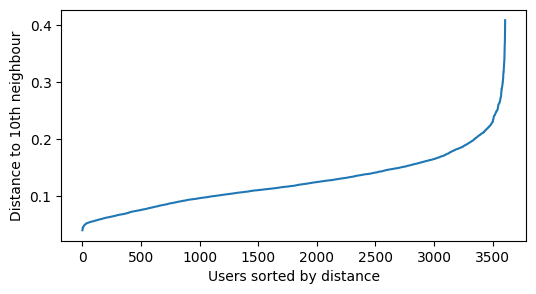

In [44]:
nn_distance = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
plt.figure(figsize=(6, 3))
plt.plot(nn_distance)
plt.xlabel("Users sorted by distance")
plt.ylabel("Distance to 10th neighbour")
plt.show()

The distance grows slowly and only rises steeply after about 0.2, so there is no single clear bend. We try $\varepsilon=0.10, 0.15$ and $0.20$.

In [45]:
def evaluate(labels):
    clustered = labels != -1
    sizes = np.bincount(labels[clustered])
    return {"clusters": len(sizes),
            "noise (% of users)": 100 * (~clustered).mean(),
            "largest cluster (% of clustered users)": 100 * sizes.max() / sizes.sum(),
            "silhouette": silhouette_score(Z[clustered], labels[clustered]) if len(sizes) > 1 else np.nan}

methods = {}
for k in [3, 4, 5]:
    methods[f"K-means (k={k})"] = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
for k in [3, 4, 5]:
    methods[f"Gaussian mixture (k={k})"] = GaussianMixture(k, n_init=3, random_state=0).fit_predict(Z)
for eps in [0.10, 0.15, 0.20]:
    methods[f"DBSCAN (eps={eps}, MinPts=10)"] = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)

pd.DataFrame({name: evaluate(labels) for name, labels in methods.items()}).T.round(2)

,clusters,noise (% of users),largest cluster (% of clustered users),silhouette
K-means (k=3),3.0,0.00,40.45,0.30
K-means (k=4),4.0,0.00,37.62,0.26
K-means (k=5),5.0,0.00,26.81,0.25
Gaussian mixture (k=3),3.0,0.00,46.24,0.09
Gaussian mixture (k=4),4.0,0.00,32.16,0.04
Gaussian mixture (k=5),5.0,0.00,36.32,0.04
"DBSCAN (eps=0.1, MinPts=10)",5.0,52.43,97.49,0.11
"DBSCAN (eps=0.15, MinPts=10)",3.0,9.90,99.45,0.37
"DBSCAN (eps=0.2, MinPts=10)",1.0,1.72,100.00,NaN


The Gaussian mixture has a much lower silhouette than K-means (0.09, 0.04 and 0.04 against 0.30, 0.26 and 0.25 for $k=3,4,5$), so its components could overlap. The silhouette is based on Euclidean distances, which is what K-means minimizes, so the comparison is a bit in favour of K-means.

DBSCAN puts nearly all clustered users (97-100 %) into one cluster for every $\varepsilon$. With $\varepsilon=0.10$ half of the users are noise, and with a larger $\varepsilon$ everything merges. The silhouette of 0.37 at $\varepsilon=0.15$ only comes from that one dominant cluster. We find no clear density gap between groups of users.

So we go with K-means, since it assigns every user, gives fairly balanced segments and has the highest silhouette of the solutions with several sizeable clusters.

### Number of clusters

Which $k$? The K-means result depends on where it starts, so it is run from 10 starting points for each $k$. We compare distortion and silhouette for $k=2,\dots,8$.

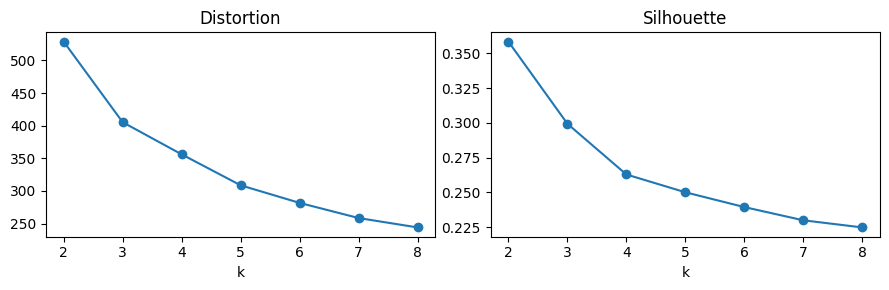

,distortion,silhouette
k,,
2,528.750,0.358
3,405.286,0.299
4,356.038,0.263
5,308.610,0.250
6,281.636,0.239
7,258.437,0.230
8,244.036,0.225


In [46]:
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    rows.append({"k": k, "distortion": km.inertia_, "silhouette": silhouette_score(Z, km.labels_)})
selection = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(selection.index, selection["distortion"], marker="o")
ax[0].set(xlabel="k", title="Distortion")
ax[1].plot(selection.index, selection["silhouette"], marker="o")
ax[1].set(xlabel="k", title="Silhouette")
plt.tight_layout()
plt.show()
selection.round(3)

Distortion keeps falling without a clear elbow. The silhouette drops fast up to $k=4$ (from about 0.36 at $k=2$ to 0.26) and then flattens (0.25 at $k=5$). Neither points to one $k$, so we look closer at $k=3$ to $6$.

What does each extra cluster add? We plot the energy profile of each cluster for $k=3,4,5,6$ and compute the the average silhouette of each clusters users.

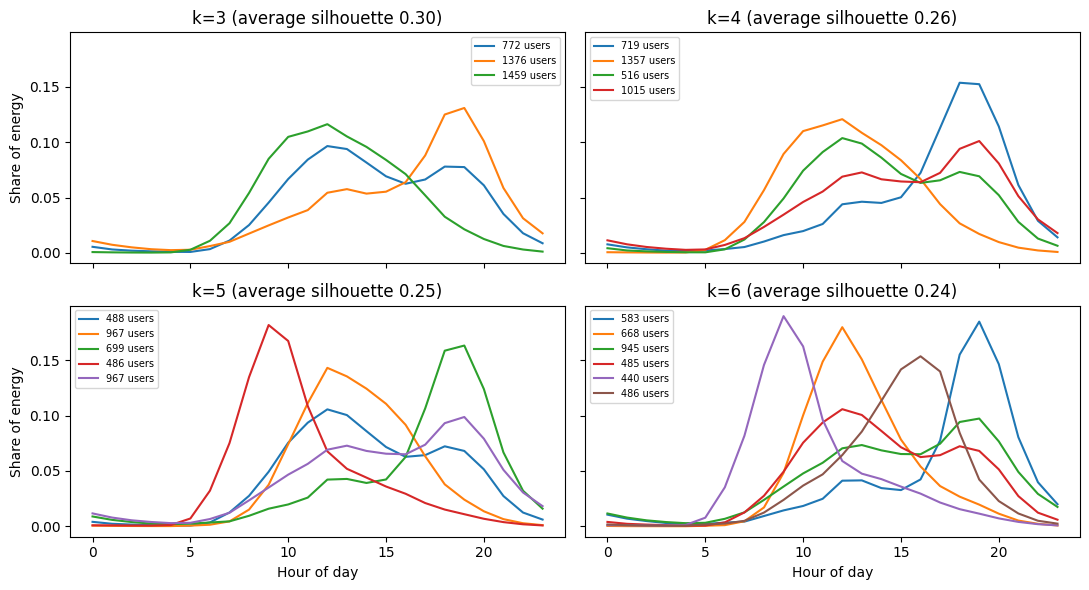

users  peak hour  weekend energy share  silhouette
k cluster                                                    
3 0          772         12                  0.69        0.28
  1         1376         19                  0.29        0.26
  2         1459         12                  0.05        0.35
4 0          719         18                  0.17        0.17
  1         1357         12                  0.05        0.34
  2          516         12                  0.77        0.22
  3         1015         19                  0.42        0.25
5 0          488         12                  0.78        0.22
  1          967         12                  0.06        0.28
  2          699         19                  0.19        0.18
  3          486          9                  0.04        0.34
  4          967         19                  0.43        0.24
6 0          583         19                  0.21        0.21
  1          668         12                  0.05        0.29
  2          945         19                  0.43        0.22
  3          485         12                  0.78        0.22
  4          440          9                  0.04        0.32
  5          486         16                  0.09        0.18

In [47]:
rows = []
fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for a, k in zip(ax.ravel(), [3, 4, 5, 6]):
    labels = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
    silhouette = pd.Series(silhouette_samples(Z, labels), index=X.index)
    profile_k = X[energy_cols].groupby(labels).mean()
    weekend_k = X["Weekend energy share"].groupby(labels).mean()
    for c in range(k):
        a.plot(range(24), profile_k.loc[c], label=f"{(labels == c).sum()} users")
        rows.append({"k": k, "cluster": c, "users": (labels == c).sum(), "peak hour": profile_k.loc[c].values.argmax(),
                     "weekend energy share": weekend_k[c], "silhouette": silhouette[labels == c].mean()})
    a.set(title=f"k={k} (average silhouette {silhouette.mean():.2f})")
    a.legend(fontsize=7)
for a in ax[1]:
    a.set_xlabel("Hour of day")
for a in ax[:, 0]:
    a.set_ylabel("Share of energy")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index(["k", "cluster"]).round(2)

This is the interpretation we have chosen for the groups under the different k-values.
- $k=3$: weekend users, weekday daytime users (peak at 12) and an evening/mixed group (peak at 19). Highest average silhouette (0.30), and groups are broad.
- $k=4$: the evening/mixed group splits into weekday evening (peak at 18) and mixed evening (peak at 19).
- $k=5$: the weekday daytime users split into morning (peak at 9) and midday (peak at 12).
- $k=6$: adds a group peaking at 16 (silhouette 0.18).

Going from 4 to 5 adds a somewhat defined segment for a small drop in average silhouette (0.26 to 0.25), while going to 6 adds a less defined one, so we choose $k=5$. It is still a judgment call on our side.

## 5. Final segmentation

K-means with $k=5$. What does each segment look like? We name the segments after the peak hour of their energy profile and their weekend share.

In [48]:
K = 5
kmeans = KMeans(K, n_init=10, random_state=0).fit(Z)
cluster = pd.Series(kmeans.labels_, index=X.index)
energy_profile = X[energy_cols].groupby(cluster).mean()
occupation_profile = X.filter(like="Occupation share h").groupby(cluster).mean()

pd.DataFrame({"users": cluster.value_counts().sort_index(),
              "peak hour": energy_profile.values.argmax(axis=1),
              "weekend energy share": X["Weekend energy share"].groupby(cluster).mean().round(2)})

,users,peak hour,weekend energy share
0,488,12,0.78
1,967,12,0.06
2,699,19,0.19
3,486,9,0.04
4,967,19,0.43


In [49]:
names = {0: "Weekend midday", 1: "Weekday midday", 2: "Weekday evening", 3: "Weekday morning", 4: "Mixed evening"}
segment_of_user = cluster.map(names)

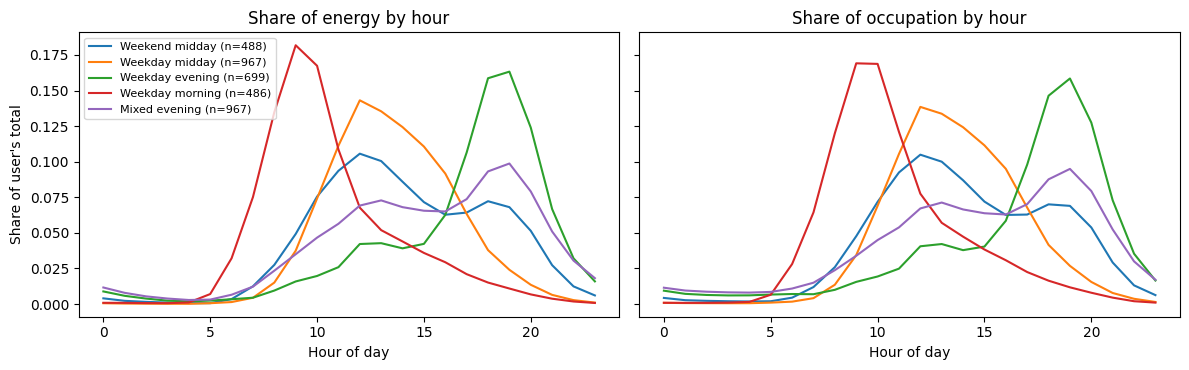

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for i, (profile, title) in enumerate([(energy_profile, "Share of energy by hour"), (occupation_profile, "Share of occupation by hour")]):
    for c, name in names.items():
        ax[i].plot(range(24), profile.loc[c].values, color=f"C{c}", label=f"{name} (n={(cluster == c).sum()})")
    ax[i].set(title=title, xlabel="Hour of day")
ax[0].set_ylabel("Share of user's total")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

The segments mostly differ in time of day (peaks at 9, 12 and 18-19) and in weekend share (4 % to 78 %). The occupation profiles still look like the energy profiles.

We plot each segment's share of its energy per day of the week, to check if patterns also hold here, for the segments.

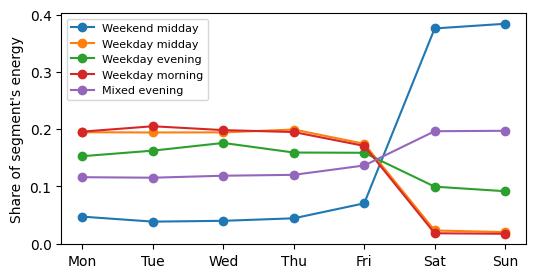

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Segment,,,,,,,
Mixed evening,11.6,11.5,11.9,12.0,13.7,19.6,19.7
Weekday evening,15.3,16.2,17.6,15.9,15.9,9.9,9.2
Weekday midday,19.5,19.4,19.4,19.9,17.4,2.3,2.0
Weekday morning,19.6,20.5,19.8,19.5,17.1,1.8,1.7
Weekend midday,4.7,3.8,4.0,4.4,7.0,37.6,38.4


In [51]:
h = hourly[hourly["User ID"].isin(X.index)]
day_share = h.groupby([h["User ID"].map(segment_of_user).rename("Segment"), "Day"])["Energy (kWh)"].sum().unstack("Day")
day_share = day_share.div(day_share.sum(axis=1), axis=0).set_axis(day_names, axis=1)

plt.figure(figsize=(6, 3))
for c, name in names.items():
    plt.plot(day_names, day_share.loc[name], marker="o", color=f"C{c}", label=name)
plt.ylabel("Share of segment's energy")
plt.legend(fontsize=8)
plt.show()

(100 * day_share).round(1)

Within Monday to Friday every segment is close, and Saturday and Sunday are also close to each other, so one weekend share seems to be enough.  
A small note on Friday is that some segments go up like weekend midday, while others like weekday midday or weekday morning go down.

Are the segments separated in the PCA space? We plot PC1 against PC2 and PC2 against PC3.

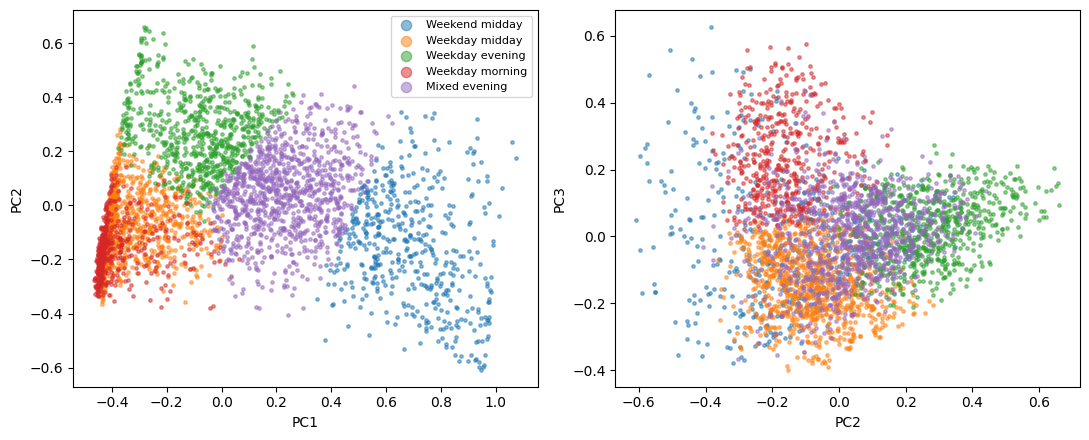

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (i, j) in zip(ax, [(0, 1), (1, 2)]):
    for c, name in names.items():
        a.scatter(Z[cluster == c, i], Z[cluster == c, j], s=6, alpha=0.5, color=f"C{c}", label=name)
    a.set(xlabel=f"PC{i + 1}", ylabel=f"PC{j + 1}")
ax[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

In PC1-PC2 the weekday morning and midday users overlap. In PC2-PC3 they separate better.

## 6. Segment characteristics

Do the segments also differ in the variables we didn't cluster on? The table compares them on:

- sessions per week: sessions over the weeks from the user's first to last session (+1 week), median user
- kWh per session and parking hours: the user's median session, median user
- idle share: share of parked hours without charging, over all of the segment's sessions
- main station share: share of the user's sessions at their most used station, median user
- living in Palo Alto: share of users with a 943xx postal code (Palo Alto, also covering Stanford and East Palo Alto). Users almost always keep one postal code, so it is computed as the mean over users of the share of their sessions with such a code
- share of energy: the segment's share of all energy

Users with fewer than 10 sessions are a reference group. Their sessions per week and main station share are left out, since most of them only have one or two sessions.

In [53]:
d["Segment"] = d["User ID"].map(segment_of_user).fillna("Occasional users (<10 sessions)")
d["Palo Alto"] = d["Driver Postal Code"].between(94300, 94399)

by_user = d.groupby("User ID")
sessions = by_user.size()
users_table = pd.DataFrame({
    "sessions per week": sessions / ((by_user["Start Date"].max() - by_user["Start Date"].min()).dt.days / 7 + 1),
    "kWh per session": by_user["Energy (kWh)"].median(),
    "parking hours": by_user["Parking Hours"].median(),
    "main station share": d.groupby(["User ID", "Station Name"]).size().groupby("User ID").max() / sessions,
    "living in Palo Alto": by_user["Palo Alto"].mean(),
    "Segment": by_user["Segment"].first()})

by_segment = users_table.groupby("Segment")
sessions_by_segment = d.groupby("Segment")
profile = pd.DataFrame({"users": by_segment.size(),
                        "sessions per week": by_segment["sessions per week"].median(),
                        "kWh per session": by_segment["kWh per session"].median(),
                        "parking hours": by_segment["parking hours"].median(),
                        "idle share": 1 - sessions_by_segment["Charging Hours"].sum() / sessions_by_segment["Parking Hours"].sum(),
                        "main station share": by_segment["main station share"].median(),
                        "living in Palo Alto": by_segment["living in Palo Alto"].mean(),
                        "share of energy": sessions_by_segment["Energy (kWh)"].sum() / d["Energy (kWh)"].sum()}).sort_values("share of energy", ascending=False)
profile.loc["Occasional users (<10 sessions)", ["sessions per week", "main station share"]] = np.nan
profile.round(2)

,users,sessions per week,kWh per session,parking hours,idle share,main station share,living in Palo Alto,share of energy
Segment,,,,,,,,
Mixed evening,967,0.22,6.01,1.53,0.27,0.34,0.44,0.25
Weekday midday,967,0.37,7.36,2.30,0.14,0.38,0.16,0.24
Weekday morning,486,0.69,8.56,2.71,0.16,0.47,0.09,0.20
Occasional users (<10 sessions),17832,NaN,6.10,1.55,0.14,NaN,0.09,0.14
Weekday evening,699,0.19,5.74,1.52,0.26,0.36,0.34,0.12
Weekend midday,488,0.19,5.25,1.31,0.15,0.36,0.25,0.05


The segments also differ in what they weren't clustered on. Weekday morning users, for example, charge most often (0.69 sessions per week), take the most energy per session (8.6 kWh), stay the longest (2.7 h) and are the most loyal to one station (0.47), while only 9 % of them live in Palo Alto. The two evening segments have the most users living in Palo Alto (34-44 %) and the most idle parked time (26-27 % against 14-16 % for the others).

### Contribution of each segment to hourly energy

Which segments drive the load at which hours? The occasional users are included (grey), since they are part of the load too. The table below the plot gives each segment's share (%) of the energy in blocks of hours.

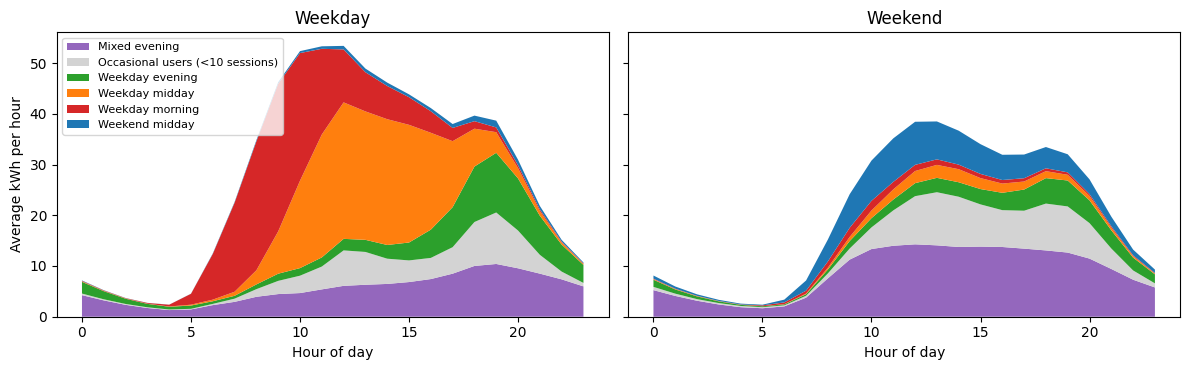

In [54]:
hourly["Segment"] = hourly["User ID"].map(segment_of_user).fillna("Occasional users (<10 sessions)")
by_hour = hourly.groupby(["Weekend", "Hour of Day", "Segment"])["Energy (kWh)"].sum().unstack("Segment")
loads = [by_hour.loc[False] / n_weekdays, by_hour.loc[True] / n_weekend_days]
color_of = {name: f"C{c}" for c, name in names.items()}
color_of["Occasional users (<10 sessions)"] = "lightgrey"

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for i, (load, title) in enumerate(zip(loads, ["Weekday", "Weekend"])):
    ax[i].stackplot(load.index, load.T.values, labels=load.columns, colors=[color_of[s] for s in load.columns])
    ax[i].set(title=title, xlabel="Hour of day")
ax[0].set_ylabel("Average kWh per hour")
ax[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

In [55]:
blocks = pd.cut(hourly["Hour of Day"], [0, 6, 10, 14, 17, 21, 24], right=False, labels=["0-6", "6-10", "10-14", "14-17", "17-21", "21-24"])
contribution = hourly.groupby(["Weekend", blocks, "Segment"], observed=True)["Energy (kWh)"].sum()
contribution = 100 * contribution / contribution.groupby(level=[0, 1], observed=True).transform("sum")
contribution.unstack(1).round().astype(int).rename(index={False: "Weekday", True: "Weekend"}, level=0)

Hour of Day                              0-6  6-10  10-14  14-17  17-21  21-24
Weekend Segment                                                               
Weekday Mixed evening                     56    12     11     16     26     46
        Occasional users (<10 sessions)    4     4     10     10     21     12
        Weekday evening                   26     3      4      9     28     35
        Weekday midday                     2    11     45     51     18      3
        Weekday morning                   11    70     29     12      4      1
        Weekend midday                     1     1      1      1      3      3
Weekend Mixed evening                     69    49     39     40     41     53
        Occasional users (<10 sessions)    8     8     22     25     26     16
        Weekday evening                   13     6      7      9     15     19
        Weekday midday                     1     3      6      6      4      2
        Weekday morning                    2     8      4      2      2      1
        Weekend midday                     7    27     23     17     12      9

On weekdays the morning users dominate 6-10 (70 % of the energy) and the midday users 10-17 (45-51 %). From 17 the two evening segments take over (54 % together in 17-21), and mixed evening users have most of the night.

On weekends mixed evening users dominate the whole day (39-69 %). Weekend midday users give 12-27 %, and the occasional users about a quarter of the daytime load.

### Does the session threshold matter?

The threshold of 10 sessions was our choice. Would the segments change with 5, 7 or 20 sessions? We rerun the pipeline (shares, PCA with 80 % of the variance, K-means with $k=5$) for each threshold and match each run's segments to the final ones by the closest average feature profile. Each cell gives the number of users in the matched segment / the peak hour of its average energy profile / its mean weekend energy share.

In [56]:
X_all = user_features(sessions_per_user[sessions_per_user >= 5].index)
reference = X.groupby(segment_of_user).mean()

rows = []
for t in [5, 7, 10, 20]:
    X_t = X_all[sessions_per_user[X_all.index] >= t]
    q_t = np.argmax(np.cumsum(PCA().fit(X_t).explained_variance_ratio_) >= 0.8) + 1
    Z_t = PCA(n_components=q_t).fit_transform(X_t)
    labels = pd.Series(KMeans(5, n_init=10, random_state=0).fit(Z_t).labels_, index=X_t.index)
    centers = X_t.groupby(labels).mean()
    match = ((centers.values[:, None] - reference.values[None]) ** 2).sum(axis=2).argmin(axis=1)
    row = {"min. sessions": t, "users": len(X_t), "silhouette": round(silhouette_score(Z_t, labels), 2)}
    for c, m in zip(centers.index, match):
        peak = X_t.loc[labels == c].filter(like="Energy share h").mean().values.argmax()
        row[reference.index[m]] = f"{(labels == c).sum()} / {peak} h / {X_t.loc[labels == c, 'Weekend energy share'].mean():.2f}"
    rows.append(row)

pd.DataFrame(rows).set_index("min. sessions")

,users,silhouette,Mixed evening,Weekday morning,Weekend midday,Weekday evening,Weekday midday
min. sessions,,,,,,,
5,5978,0.24,1703 / 19 h / 0.45,848 / 10 h / 0.04,907 / 12 h / 0.81,1079 / 19 h / 0.15,1441 / 12 h / 0.08
7,4689,0.24,1341 / 19 h / 0.44,655 / 9 h / 0.04,666 / 12 h / 0.80,869 / 19 h / 0.16,1158 / 12 h / 0.06
10,3607,0.25,967 / 19 h / 0.43,486 / 9 h / 0.04,488 / 12 h / 0.78,699 / 19 h / 0.19,967 / 12 h / 0.06
20,2215,0.27,589 / 19 h / 0.41,329 / 9 h / 0.04,276 / 12 h / 0.75,386 / 18 h / 0.19,635 / 12 h / 0.05


The same five segments show up for every threshold. Their peak hours and weekend energy shares barely change (two peaks move by one hour), mostly the sizes do, and the silhouette stays at 0.24-0.27.

The segments don't seem to be an artefact of the threshold, so we keep 10. It covers about 84 % of the sessions.

## 7. Findings

| Segment | Users | Peak hour | Weekend share of energy | Sessions per week | kWh per session | Parking hours | Idle share | Main station share | Living in Palo Alto | Share of energy |
|---|---|---|---|---|---|---|---|---|---|---|
| Weekday morning | 486 | 9 | 4 % | 0.69 | 8.6 | 2.7 | 16 % | 0.47 | 9 % | 20 % |
| Weekday midday | 967 | 12 | 6 % | 0.37 | 7.4 | 2.3 | 14 % | 0.38 | 16 % | 24 % |
| Weekday evening | 699 | 19 | 19 % | 0.19 | 5.7 | 1.5 | 26 % | 0.36 | 34 % | 12 % |
| Mixed evening | 967 | 19 | 43 % | 0.22 | 6.0 | 1.5 | 27 % | 0.34 | 44 % | 25 % |
| Weekend midday | 488 | 12 | 78 % | 0.19 | 5.3 | 1.3 | 15 % | 0.36 | 25 % | 5 % |
| Occasional (<10 sessions) | 17,832 | n/a | n/a | n/a | 6.1 | 1.6 | 14 % | n/a | 9 % | 14 % |

- The weekday morning users are about 2 % of all users and give 20 % of all energy.
- Within Monday to Friday every segment is close to flat, so one weekend share is enough. Fridays lean slightly towards the weekend for the weekend midday and mixed evening users.
- On weekdays the load goes from weekday morning (6-10) to weekday midday (10-17) to the evening segments (from 17). On weekends mixed evening users dominate, and occasional users give about a quarter of the daytime load.
- The average silhouette is only 0.25, and neither the Gaussian mixture nor DBSCAN finds clearly separated groups, so the segments split a continuum with soft borders. $k=5$ is a judgment call; $k=4$ would merge the weekday morning and midday users.